In [1]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

from pathlib import Path

import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG_DIR = Path("../../fig/H7")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
YEAR_MIN, YEAR_MAX = 1877, 1939
AGE_MIN, AGE_MAX = 15, 24
NACHTCATS = ["nacht", "avondschemering", "ochtendschemering"]
DAGCATS = ["dag"]

WIJK_SAMENVOEGEN = {7: 6, 11: 5}
WIJKEN = ["1", "3", "5", "6"]
TITELS = {"1": "wijk 1", "3": "wijk 3", "5": "wijk 5–11", "6": "wijk 6–7"}
KLEUREN_DD = {"dag": KLEUR_DAG, "nacht": KLEUR_NACHT}

DF_SPLINE = 4
PRIOR_SPLINE = bmb.Prior("Normal", mu=0, sigma=1)

plt.rcParams.update({
    "font.family": "Libertinus Serif",
    "font.size": CORPS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [2]:
DATA_DIR = Path("../../data/algemeen/gebeurtenisdata_macro")

df = pd.concat(
    [pd.read_excel(f) for f in sorted(DATA_DIR.glob("*.xlsx"))
     if not f.name.startswith(("~$", "._"))],
    ignore_index=True,
).dropna(subset=["year"])
df["P_AGE_clean"] = pd.to_numeric(df["P_AGE_clean"], errors="coerce")

In [3]:
model_data = df[
    df["gender_inferred"].isin(["man", "woman"])
    & df["year"].between(YEAR_MIN, YEAR_MAX)
    & df["P_AGE_clean"].between(AGE_MIN, AGE_MAX)
    & df["astro"].isin(NACHTCATS + DAGCATS)
].copy()
model_data["nacht"] = model_data["astro"].isin(NACHTCATS).astype(int)

YEAR_MEAN = (model_data.groupby(["year", "gender_inferred"]).size()
             .reset_index()["year"].mean())
print(f"{len(model_data):,} registraties | YEAR_MEAN = {YEAR_MEAN:.2f}")

10,826 registraties | YEAR_MEAN = 1907.80


In [4]:
dagdeel_data = (
    model_data
    .assign(
        wijk=lambda d: d["district"].replace(WIJK_SAMENVOEGEN),
        vrouw=lambda d: d["gender_inferred"].eq("woman").astype(int),
        dagdeel=lambda d: np.where(d["nacht"] == 1, "nacht", "dag"),
    )
    .dropna(subset=["wijk"])
    .assign(wijk=lambda d: d["wijk"].astype(int).astype(str))
    .query("wijk in @WIJKEN")
    .groupby(["year", "wijk", "dagdeel"])["vrouw"]
    .agg(n_vrouw="sum", n_tot="size")
    .reset_index()
)
dagdeel_data["jaar_c"] = dagdeel_data["year"] - YEAR_MEAN
dagdeel_data["wijk_dagdeel"] = dagdeel_data["wijk"] + "_" + dagdeel_data["dagdeel"]

print(f"{len(dagdeel_data)} cellen | N = {dagdeel_data['n_tot'].sum():,}")  # moet 10.401 zijn

182 cellen | N = 10,401


In [5]:
TERM_SPLINE = f"bs(jaar_c, df={DF_SPLINE}):wijk_dagdeel"

model_dagdeel = bmb.Model(
    f"p(n_vrouw, n_tot) ~ 0 + wijk_dagdeel + {TERM_SPLINE}",
    data=dagdeel_data,
    family="beta_binomial",
    priors={TERM_SPLINE: PRIOR_SPLINE},
)
idata_dagdeel = model_dagdeel.fit(draws=1000, tune=1000, chains=4, cores=4,
                                  target_accept=0.9, random_seed=SEED)

diag = az.summary(idata_dagdeel)[["r_hat", "ess_bulk"]]
print(f"max r_hat {diag['r_hat'].max():.3f} | min ESS {diag['ess_bulk'].min():.0f} | "
      f"divergenties {int(idata_dagdeel.sample_stats['diverging'].sum())}")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [kappa, wijk_dagdeel, bs(jaar_c, df=4):wijk_dagdeel]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 13 seconds.


max r_hat 1.000 | min ESS 1626 | divergenties 0


In [6]:
bereik = dagdeel_data.groupby("wijk")["year"].agg(["min", "max"])

grid = pd.DataFrame(
    [(w, d, j) for w in WIJKEN for d in ["dag", "nacht"]
     for j in range(bereik.loc[w, "min"], bereik.loc[w, "max"] + 1)],
    columns=["wijk", "dagdeel", "year"],
)
grid["wijk_dagdeel"] = grid["wijk"] + "_" + grid["dagdeel"]
grid["jaar_c"] = grid["year"] - YEAR_MEAN
met_data = set(zip(dagdeel_data["wijk"], dagdeel_data["year"]))
grid["data"] = [(w, j) in met_data for w, j in zip(grid["wijk"], grid["year"])]

pred = model_dagdeel.predict(idata_dagdeel, data=grid, kind="response_params", inplace=False)
mu = pred.posterior["mu"].stack(sample=("chain", "draw")).values

aandeel = grid.copy()
aandeel["mediaan"] = np.median(mu, axis=1)
aandeel["lo94"], aandeel["lo50"], aandeel["hi50"], aandeel["hi94"] = np.percentile(
    mu, [3, 25, 75, 97], axis=1)

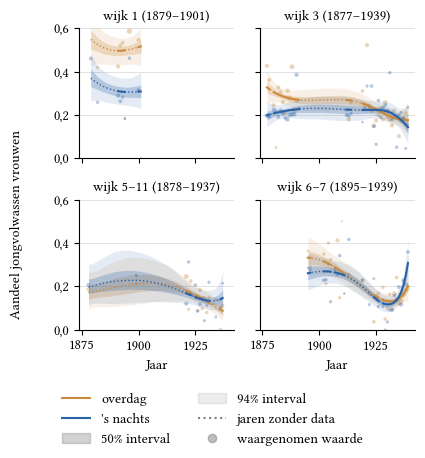

In [ ]:
def lijn_met_gaten(ax, sel, kleur):
    """Doorgetrokken waar data zijn, gestippeld over ontbrekende jaren."""
    ax.plot(sel["year"], sel["mediaan"], ":", color=kleur, lw=1)
    ax.plot(sel["year"], sel["mediaan"].where(sel["data"]), "-", color=kleur)


fig, axes = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, 4.6), sharex=True, sharey=True)

for ax, w in zip(axes.flat, WIJKEN):
    for d in ["dag", "nacht"]:
        sel = aandeel[(aandeel["wijk"] == w) & (aandeel["dagdeel"] == d)]
        ax.fill_between(sel["year"], sel["lo94"], sel["hi94"], color=KLEUREN_DD[d], alpha=0.12, lw=0)
        ax.fill_between(sel["year"], sel["lo50"], sel["hi50"], color=KLEUREN_DD[d], alpha=0.25, lw=0)
        lijn_met_gaten(ax, sel, KLEUREN_DD[d])

        obs = dagdeel_data[(dagdeel_data["wijk"] == w) & (dagdeel_data["dagdeel"] == d)]
        ax.scatter(obs["year"], obs["n_vrouw"] / obs["n_tot"], s=np.sqrt(obs["n_tot"]),
                   color=KLEUREN_DD[d], alpha=0.35, lw=0)

    ax.set_title(f"{TITELS[w]} ({bereik.loc[w, 'min']}–{bereik.loc[w, 'max']})", fontsize=CORPS)
    ax.set_ylim(0, 0.6)
    ax.yaxis.grid(True)

for ax in axes[1]:
    ax.set_xlabel("Jaar")
fig.supylabel("Aandeel jongvolwassen vrouwen", fontsize=CORPS)

handles = [
    plt.Line2D([], [], color=KLEUREN_DD["dag"], label="overdag"),
    plt.Line2D([], [], color=KLEUREN_DD["nacht"], label="'s nachts"),
    plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.35, label="50% interval"),
    plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.15, label="94% interval"),
    plt.Line2D([], [], ls=":", color="grey", label="jaren zonder data"),
    plt.Line2D([], [], ls="", marker="o", color="grey", alpha=0.5, label="waargenomen waarde"),
]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=CORPS)
fig.tight_layout(rect=[0.02, 0.15, 1, 1])
for ext in ("png",):
    pas_breedte_aan(fig, tight=True)
    fig.savefig(FIG_DIR / f"7.2_aandeel_vrouwen_dag_nacht.{ext}", dpi=300, bbox_inches="tight")

In [8]:
TERM_SPLINE_DD = f"bs(jaar_c, df={DF_SPLINE}):dagdeel"
PRIOR_WIJK = bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=0.5))

model_pool = bmb.Model(
    f"p(n_vrouw, n_tot) ~ 0 + dagdeel + {TERM_SPLINE_DD} + (1 + dagdeel | wijk)",
    data=dagdeel_data,
    family="beta_binomial",
    priors={
        TERM_SPLINE_DD: PRIOR_SPLINE,
        "1|wijk": PRIOR_WIJK,
        "dagdeel|wijk": PRIOR_WIJK,
    },
)
idata_pool = model_pool.fit(draws=1000, tune=1000, chains=4, cores=4,
                            target_accept=0.95, random_seed=SEED)

diag = az.summary(idata_pool)[["r_hat", "ess_bulk"]]
print(f"max r_hat {diag['r_hat'].max():.3f} | min ESS {diag['ess_bulk'].min():.0f} | "
      f"divergenties {int(idata_pool.sample_stats['diverging'].sum())}")
print(az.summary(idata_pool, var_names=["dagdeel|wijk", "1|wijk_sigma", "dagdeel|wijk_sigma"],
                 hdi_prob=0.94))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [kappa, dagdeel, bs(jaar_c, df=4):dagdeel, 1|wijk_sigma, 1|wijk_offset, dagdeel|wijk_sigma, dagdeel|wijk_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 34 seconds.


There were 1 divergences after tuning. Increase `target_accept` or reparameterize.


max r_hat 1.000 | min ESS 1379 | divergenties 1
                            mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  \
dagdeel|wijk[nacht, 1]    -0.130  0.193  -0.526    0.148      0.004    0.003   
dagdeel|wijk[nacht, 3]     0.019  0.148  -0.269    0.325      0.003    0.002   
dagdeel|wijk[nacht, 5]     0.060  0.177  -0.257    0.440      0.003    0.002   
dagdeel|wijk[nacht, 6]     0.041  0.154  -0.245    0.361      0.003    0.002   
1|wijk_sigma               0.528  0.197   0.209    0.888      0.004    0.003   
dagdeel|wijk_sigma[nacht]  0.187  0.167   0.000    0.483      0.004    0.003   

                           ess_bulk  ess_tail  r_hat  
dagdeel|wijk[nacht, 1]       2516.0    3192.0    1.0  
dagdeel|wijk[nacht, 3]       3168.0    2853.0    1.0  
dagdeel|wijk[nacht, 5]       3575.0    3390.0    1.0  
dagdeel|wijk[nacht, 6]       3129.0    3089.0    1.0  
1|wijk_sigma                 1946.0    2451.0    1.0  
dagdeel|wijk_sigma[nacht]    1849.0    1810.0    1.0  


In [9]:
pred = model_pool.predict(idata_pool, data=grid, kind="response_params", inplace=False)
mu_pool = pred.posterior["mu"].stack(sample=("chain", "draw")).values

aandeel_pool = grid.copy()
aandeel_pool["mediaan"] = np.median(mu_pool, axis=1)
aandeel_pool["lo94"], aandeel_pool["lo50"], aandeel_pool["hi50"], aandeel_pool["hi94"] = \
    np.percentile(mu_pool, [3, 25, 75, 97], axis=1)

# verschil nacht − dag per wijk, gemiddeld over de jaren met data in die wijk
rijen = []
for w in WIJKEN:
    sel = grid[(grid["wijk"] == w) & grid["data"]]
    dag = mu_pool[sel[sel["dagdeel"] == "dag"].index].mean(axis=0)
    nacht = mu_pool[sel[sel["dagdeel"] == "nacht"].index].mean(axis=0)
    verschil = (nacht - dag) * 100
    rijen.append({
        "wijk": TITELS[w],
        "dag (%)": round(np.median(dag) * 100, 1),
        "nacht (%)": round(np.median(nacht) * 100, 1),
        "verschil (pp)": round(np.median(verschil), 1),
        "94%-interval": tuple(np.percentile(verschil, [3, 97]).round(1)),
        "P(nacht < dag)": round((verschil < 0).mean(), 2),
    })
print(pd.DataFrame(rijen).to_string(index=False))

     wijk  dag (%)  nacht (%)  verschil (pp)  94%-interval  P(nacht < dag)
   wijk 1     47.3       34.7          -12.3 (-21.3, -5.8)            1.00
   wijk 3     24.4       21.3           -3.2  (-6.0, -0.4)            0.98
wijk 5–11     15.6       15.2           -0.5   (-3.9, 3.6)            0.62
 wijk 6–7     21.4       20.0           -1.4   (-4.6, 2.3)            0.78


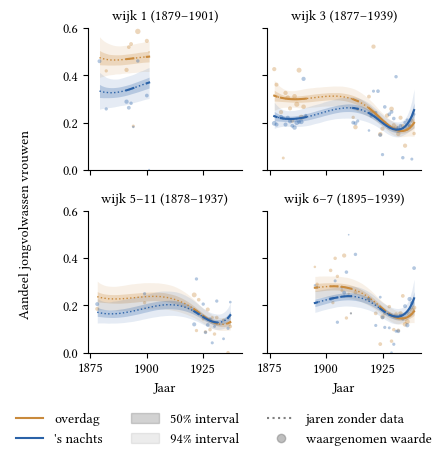

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, 4.6), sharex=True, sharey=True)

for ax, w in zip(axes.flat, WIJKEN):
    for d in ["dag", "nacht"]:
        sel = aandeel_pool[(aandeel_pool["wijk"] == w) & (aandeel_pool["dagdeel"] == d)]
        ax.fill_between(sel["year"], sel["lo94"], sel["hi94"], color=KLEUREN_DD[d], alpha=0.12, lw=0)
        ax.fill_between(sel["year"], sel["lo50"], sel["hi50"], color=KLEUREN_DD[d], alpha=0.25, lw=0)
        lijn_met_gaten(ax, sel, KLEUREN_DD[d])

        obs = dagdeel_data[(dagdeel_data["wijk"] == w) & (dagdeel_data["dagdeel"] == d)]
        ax.scatter(obs["year"], obs["n_vrouw"] / obs["n_tot"], s=np.sqrt(obs["n_tot"]),
                   color=KLEUREN_DD[d], alpha=0.35, lw=0)

    ax.set_title(f"{TITELS[w]} ({bereik.loc[w, 'min']}–{bereik.loc[w, 'max']})", fontsize=CORPS)
    ax.set_ylim(0, 0.6)

for ax in axes[1]:
    ax.set_xlabel("Jaar")
fig.supylabel("Aandeel jongvolwassen vrouwen", fontsize=CORPS)
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=CORPS)
fig.tight_layout(rect=[0.02, 0.1, 1, 1])
#for ext in ("png",):
#    fig.savefig(FIG_DIR / f"aandeel_vrouwen_dag_nacht_gepoold.{ext}", dpi=300, bbox_inches="tight")